CovidPos values:
CovidPos
No                                                               270055
Yes                                                              110877
NaN                                                               50764
Tested positive using home test without a health professional     13436
Name: count, dtype: int64
Target distribution:
 0.0    270055
1.0    124313
Name: count, dtype: int64
Numeric: 6, Categorical: 33
Train: (315494, 39), Test: (78874, 39)
Final feature count: 39
Train: (315494, 39), Test: (78874, 39)
Training lr=0.01 with class_weight='balanced' ...
Training lr=0.1 with class_weight='balanced' ...
Training lr=0.5 with class_weight='balanced' ...


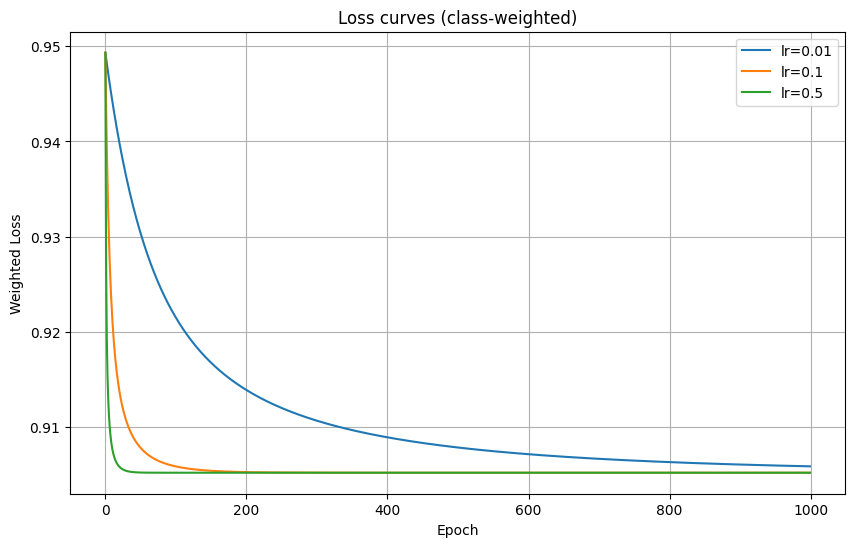

lr=0.01: Acc=0.5964, Prec=0.4086, Rec=0.6266, AUC=0.6423
lr=0.1: Acc=0.5954, Prec=0.4076, Rec=0.6253, AUC=0.6429
lr=0.5: Acc=0.5953, Prec=0.4075, Rec=0.6252, AUC=0.6430


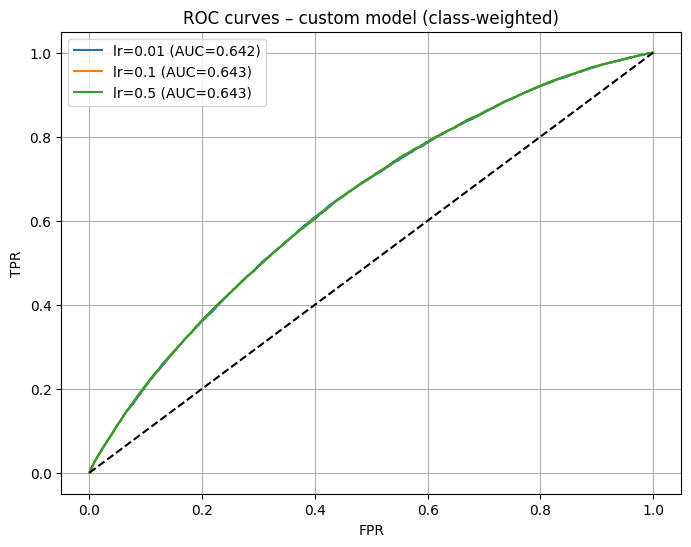

sklearn (weighted): Acc=0.5954, Prec=0.4076, Rec=0.6256, AUC=0.6429
Custom (0.01, weighted): Acc=0.5964, Prec=0.4086, Rec=0.6266, AUC=0.6423


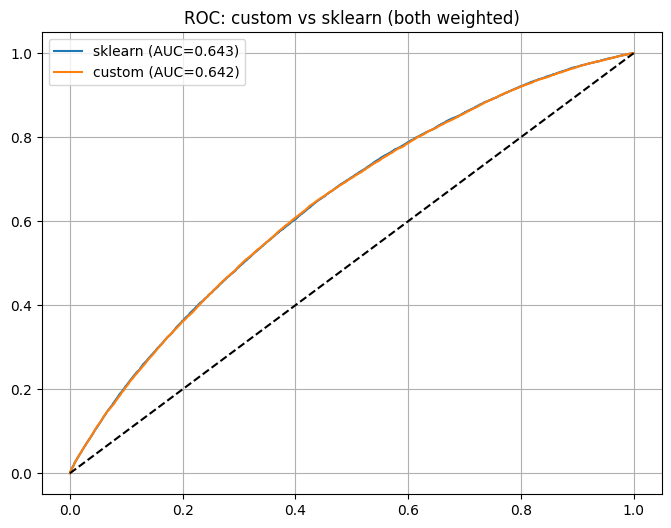

Top 20 features by |correlation|:
  AgeCategory                         corr=+0.1821
  RemovedTeeth                        corr=+0.0768
  State                               corr=+0.0765
  PneumoVaxEver                       corr=+0.0754
  HIVTesting                          corr=+0.0731
  WeightInKilograms                   corr=+0.0623
  BMI                                 corr=+0.0606
  FluVaxLast12                        corr=+0.0596
  TetanusLast10Tdap                   corr=+0.0550
  AlcoholDrinkers                     corr=+0.0537
  HighRiskLastYear                    corr=+0.0514
  SmokerStatus                        corr=+0.0504
  ECigaretteUsage                     corr=+0.0491
  RaceEthnicityCategory               corr=+0.0483
  DifficultyWalking                   corr=+0.0456
  SleepHours                          corr=-0.0450
  MentalHealthDays                    corr=+0.0443
  HadAsthma                           corr=+0.0434
  HadArthritis                        corr=+0.03

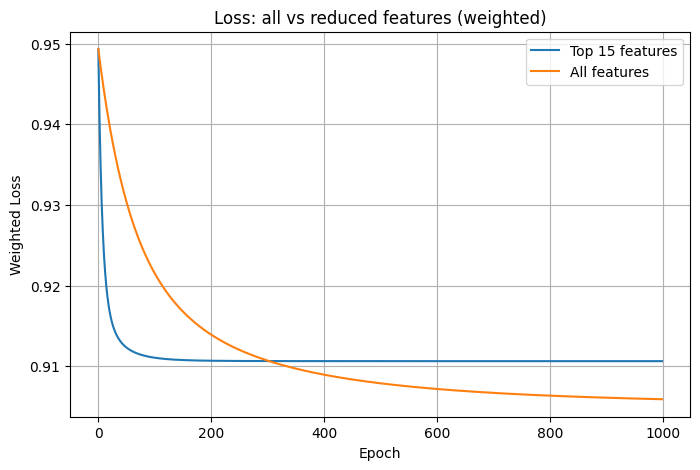

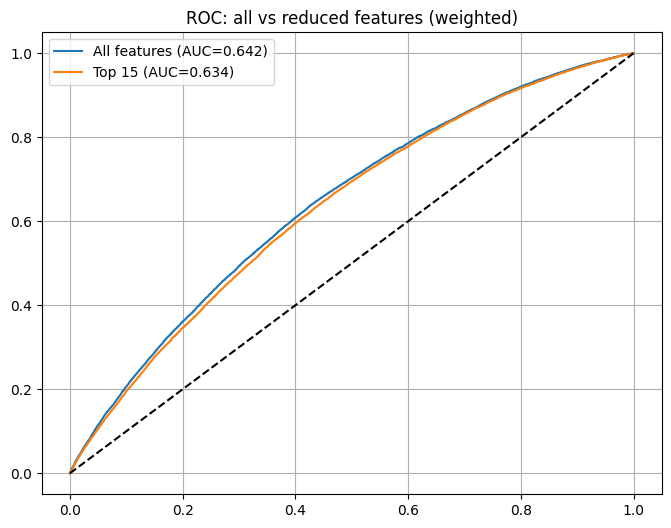

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_curve, roc_auc_score
)

from LogisticRegression import LogisticRegression

df = pd.read_csv("Covid_pula_pula_bompa.csv")
print("CovidPos values:")
print(df['CovidPos'].value_counts(dropna=False))

# Target mapping: Yes and home-test positive: 1, No: 0, drop true NaN
positive_labels = ['Yes', 'Tested positive using home test without a health professional']
df['target'] = df['CovidPos'].apply(lambda x: 1 if x in positive_labels else (0 if x == 'No' else np.nan))
df_clean = df.dropna(subset=['target']).copy()
y = df_clean['target'].values.astype(np.float64)
X = df_clean.drop(['CovidPos', 'target'], axis=1)
print("Target distribution:\n", pd.Series(y).value_counts())

# Identify column types
numeric_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Numeric: {len(numeric_cols)}, Categorical: {len(categorical_cols)}")

train_idx, test_idx = train_test_split(
    np.arange(len(y)), test_size=0.2, random_state=42, stratify=y
)
y_train_raw = y[train_idx]
y_test_raw  = y[test_idx]
X_train_raw = X.iloc[train_idx].copy()
X_test_raw  = X.iloc[test_idx].copy()

print(f"Train: {X_train_raw.shape}, Test: {X_test_raw.shape}")

# Preprocessing function
def safe_float(arr_col):
    out = np.full(len(arr_col), np.nan, dtype=np.float64)
    for i, val in enumerate(arr_col):
        try:
            out[i] = float(val)
        except (ValueError, TypeError):
            pass
    return out

def impute_numeric(train_col, test_col):
    train_vals = safe_float(train_col.values)
    median = np.nanmedian(train_vals)
    train_vals = np.where(np.isnan(train_vals), median, train_vals)
    test_vals  = safe_float(test_col.values)
    test_vals  = np.where(np.isnan(test_vals), median, test_vals)
    return train_vals, test_vals

def target_encode_categorical(train_col, test_col, y_train):
    def clean_series(col):
        s = col.astype(str).copy()
        s[s.isin(['nan', 'None', '', 'NaN', 'null', 'NULL', 'NA'])] = 'MISSING'
        return s
    train_s = clean_series(train_col)
    test_s  = clean_series(test_col)
    unique_cats = np.unique(train_s)
    cat_mean = {}
    global_mean = np.mean(y_train)
    for cat in unique_cats:
        mask = (train_s == cat).values
        if np.any(mask):
            cat_mean[cat] = np.mean(y_train[mask])
    train_enc = np.array([cat_mean.get(c, global_mean) for c in train_s])
    test_enc  = np.array([cat_mean.get(c, global_mean) for c in test_s])
    return train_enc, test_enc

def standardize(train_arr, test_arr):
    mean = np.mean(train_arr, axis=0)
    std  = np.std(train_arr, axis=0)
    std[std == 0] = 1e-8
    return (train_arr - mean) / std, (test_arr - mean) / std

# Build processed feature matrices
train_parts = []
test_parts  = []
for col in numeric_cols:
    t, te = impute_numeric(X_train_raw[col], X_test_raw[col])
    train_parts.append(t.reshape(-1, 1))
    test_parts.append(te.reshape(-1, 1))
for col in categorical_cols:
    t_enc, te_enc = target_encode_categorical(X_train_raw[col], X_test_raw[col], y_train_raw)
    train_parts.append(t_enc.reshape(-1, 1))
    test_parts.append(te_enc.reshape(-1, 1))

X_train_proc = np.hstack(train_parts)
X_test_proc  = np.hstack(test_parts)
X_train, X_test = standardize(X_train_proc, X_test_proc)

print(f"Final feature count: {X_train.shape[1]}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Part A: Training with weighted loss
learning_rates = [0.01, 0.1, 0.5]
epochs = 1000
models, histories = {}, {}

for lr in learning_rates:
    print(f"Training lr={lr} with class_weight='balanced' ...")
    model = LogisticRegression(learning_rate=lr, epochs=epochs, class_weight='balanced', verbose=False)
    model.fit(X_train, y_train_raw)
    models[lr] = model
    histories[lr] = model.loss_history

plt.figure(figsize=(10,6))
for lr, loss in histories.items():
    plt.plot(loss, label=f'lr={lr}')
plt.xlabel('Epoch'); plt.ylabel('Weighted Loss')
plt.title('Loss curves (class-weighted)')
plt.legend(); plt.grid(True); plt.show()

def evaluate_model(model, X, y_true):
    y_pred = model.predict(X)           # threshold = 0.5
    y_prob = model.predict_proba(X)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    return acc, prec, rec, fpr, tpr, auc

results_a = {}
for lr, model in models.items():
    acc, prec, rec, fpr, tpr, auc = evaluate_model(model, X_test, y_test_raw)
    results_a[lr] = (acc, prec, rec, fpr, tpr, auc)
    print(f"lr={lr}: Acc={acc:.4f}, Prec={prec:.4f}, Rec={rec:.4f}, AUC={auc:.4f}")

plt.figure(figsize=(8,6))
for lr, (_, _, _, fpr, tpr, auc) in results_a.items():
    plt.plot(fpr, tpr, label=f'lr={lr} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('ROC curves – custom model (class‑weighted)')
plt.legend(); plt.grid(True); plt.show()

# Part B: Compare with scikit‑learn LogisticRegression

from sklearn.linear_model import LogisticRegression as SklearnLR

sk_model = SklearnLR(max_iter=1000, class_weight='balanced', random_state=42)
sk_model.fit(X_train, y_train_raw)
y_pred_sk = sk_model.predict(X_test)
y_prob_sk = sk_model.predict_proba(X_test)[:,1]

acc_sk = accuracy_score(y_test_raw, y_pred_sk)
prec_sk = precision_score(y_test_raw, y_pred_sk, zero_division=0)
rec_sk = recall_score(y_test_raw, y_pred_sk, zero_division=0)
fpr_sk, tpr_sk, _ = roc_curve(y_test_raw, y_prob_sk)
auc_sk = roc_auc_score(y_test_raw, y_prob_sk)

print(f"sklearn (weighted): Acc={acc_sk:.4f}, Prec={prec_sk:.4f}, Rec={rec_sk:.4f}, AUC={auc_sk:.4f}")
best_lr = 0.01
acc_c, prec_c, rec_c, _, _, auc_c = results_a[best_lr]
print(f"Custom ({best_lr}, weighted): Acc={acc_c:.4f}, Prec={prec_c:.4f}, Rec={rec_c:.4f}, AUC={auc_c:.4f}")

plt.figure(figsize=(8,6))
plt.plot(fpr_sk, tpr_sk, label=f'sklearn (AUC={auc_sk:.3f})')
plt.plot(results_a[best_lr][3], results_a[best_lr][4], label=f'custom (AUC={auc_c:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.legend(); plt.grid(True)
plt.title('ROC: custom vs sklearn (both weighted)'); plt.show()

# Part C: Feature selection using correlation matrix (with weighted model)

feature_names = numeric_cols + categorical_cols
feature_corr = []
for i in range(X_train.shape[1]):
    corr = np.corrcoef(X_train[:, i], y_train_raw)[0, 1]
    feature_corr.append((i, abs(corr), corr))

sorted_feat = sorted(feature_corr, key=lambda x: x[1], reverse=True)
print("Top 20 features by |correlation|:")
for idx, abs_c, corr in sorted_feat[:20]:
    print(f"  {feature_names[idx]:35s} corr={corr:+.4f}")

top_k = 15
selected_idx = [i for i, _, _ in sorted_feat[:top_k]]
X_train_red = X_train[:, selected_idx]
X_test_red  = X_test[:, selected_idx]

model_red = LogisticRegression(learning_rate=0.1, epochs=1000, class_weight='balanced')
model_red.fit(X_train_red, y_train_raw)

acc_r, prec_r, rec_r, fpr_r, tpr_r, auc_r = evaluate_model(model_red, X_test_red, y_test_raw)
print(f"Top {top_k} features (weighted): Acc={acc_r:.4f}, Prec={prec_r:.4f}, Rec={rec_r:.4f}, AUC={auc_r:.4f}")

plt.figure(figsize=(8,5))
plt.plot(model_red.loss_history, label=f'Top {top_k} features')
plt.plot(histories[best_lr], label='All features')
plt.xlabel('Epoch'); plt.ylabel('Weighted Loss')
plt.legend(); plt.grid(True)
plt.title('Loss: all vs reduced features (weighted)')
plt.show()

plt.figure(figsize=(8,6))
plt.plot(results_a[best_lr][3], results_a[best_lr][4], label=f'All features (AUC={results_a[best_lr][5]:.3f})')
plt.plot(fpr_r, tpr_r, label=f'Top {top_k} (AUC={auc_r:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.legend(); plt.grid(True)
plt.title('ROC: all vs reduced features (weighted)')
plt.show()